In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("mymoviedb.csv", engine='python', on_bad_lines='skip')

In [ ]:
print("Dataset Shape:", df.shape)

print("\nColumns:")
print(df.columns)

print("\nData Types:")
print(df.dtypes)


Dataset Shape: (9837, 9)

Columns:
Index(['Release_Date', 'Title', 'Overview', 'Popularity', 'Vote_Count',
       'Vote_Average', 'Original_Language', 'Genre', 'Poster_Url'],
      dtype='object')

Data Types:
Release_Date          object
Title                 object
Overview              object
Popularity           float64
Vote_Count            object
Vote_Average          object
Original_Language     object
Genre                 object
Poster_Url            object
dtype: object


In [ ]:
print("\nMissing Values:")
print(df.isnull().sum())


Missing Values:
Release_Date          0
Title                 9
Overview              9
Popularity           10
Vote_Count           10
Vote_Average         10
Original_Language    10
Genre                11
Poster_Url           11
dtype: int64


In [ ]:
print("\nDuplicate Rows:", df.duplicated().sum())


Duplicate Rows: 0


In [ ]:
# Remove duplicates
df.drop_duplicates(inplace=True)

# Remove missing values
df.dropna(inplace=True)

# Convert Release_Date to datetime format
df['Release_Date'] = pd.to_datetime(
    df['Release_Date'],
    errors='coerce'
)


In [ ]:
# Remove invalid dates
df.dropna(subset=['Release_Date'], inplace=True)

In [ ]:
# Reset Index
df.reset_index(drop=True, inplace=True)

print("\nCleaned Dataset Shape:", df.shape)



Cleaned Dataset Shape: (9826, 9)


In [ ]:
print("\nStatistical Summary:")
print(df.describe())


Statistical Summary:
                        Release_Date   Popularity
count                           9826  9826.000000
mean   2006-09-23 04:47:14.276409600    40.323951
min              1902-04-17 00:00:00    13.354000
25%              2000-10-17 12:00:00    16.128250
50%              2011-09-12 00:00:00    21.195000
75%              2017-11-22 00:00:00    35.179250
max              2024-07-03 00:00:00  5083.954000
std                              NaN   108.879332


In [ ]:
print("\nTop 10 Genres:")
print(df['Genre'].value_counts().head(10))


Top 10 Genres:
Genre
Drama                     466
Comedy                    403
Drama, Romance            248
Horror                    238
Horror, Thriller          199
Comedy, Romance           196
Documentary               139
Comedy, Drama             137
Action, Thriller          125
Comedy, Drama, Romance    107
Name: count, dtype: int64


In [ ]:
print("\nTop Languages:")
print(df['Original_Language'].value_counts().head(10))



Top Languages:
Original_Language
en    7569
ja     645
es     339
fr     292
ko     170
zh     129
it     123
cn     109
ru      83
de      82
Name: count, dtype: int64


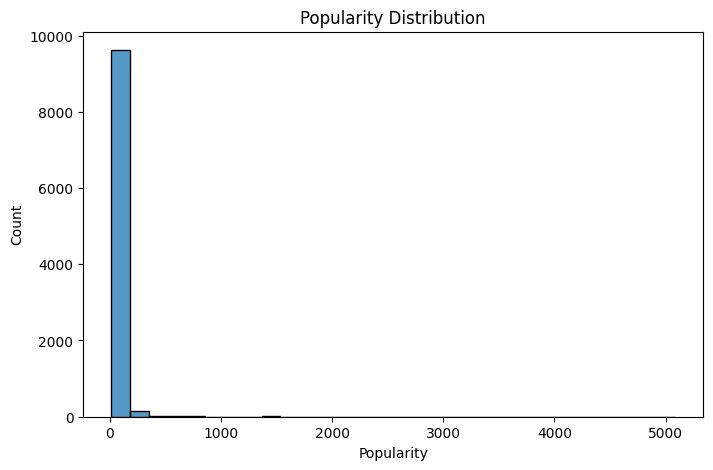

In [ ]:
plt.figure(figsize=(8,5))
sns.histplot(df['Popularity'], bins=30)
plt.title("Popularity Distribution")
plt.xlabel("Popularity")
plt.ylabel("Count")
plt.show()


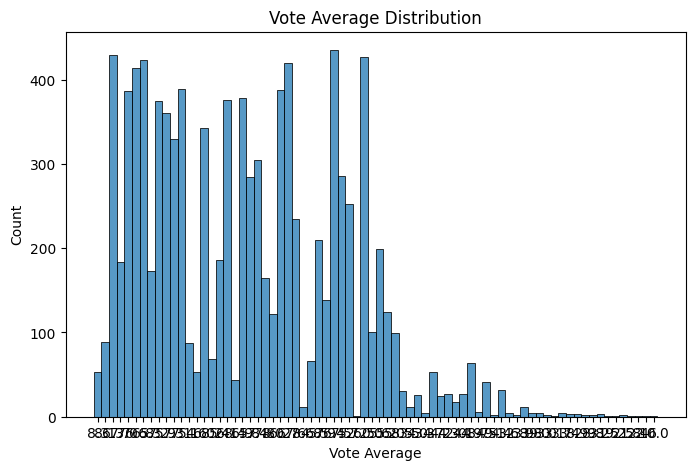

In [ ]:
plt.figure(figsize=(8,5))
sns.histplot(df['Vote_Average'], bins=20)
plt.title("Vote Average Distribution")
plt.xlabel("Vote Average")
plt.ylabel("Count")
plt.show()


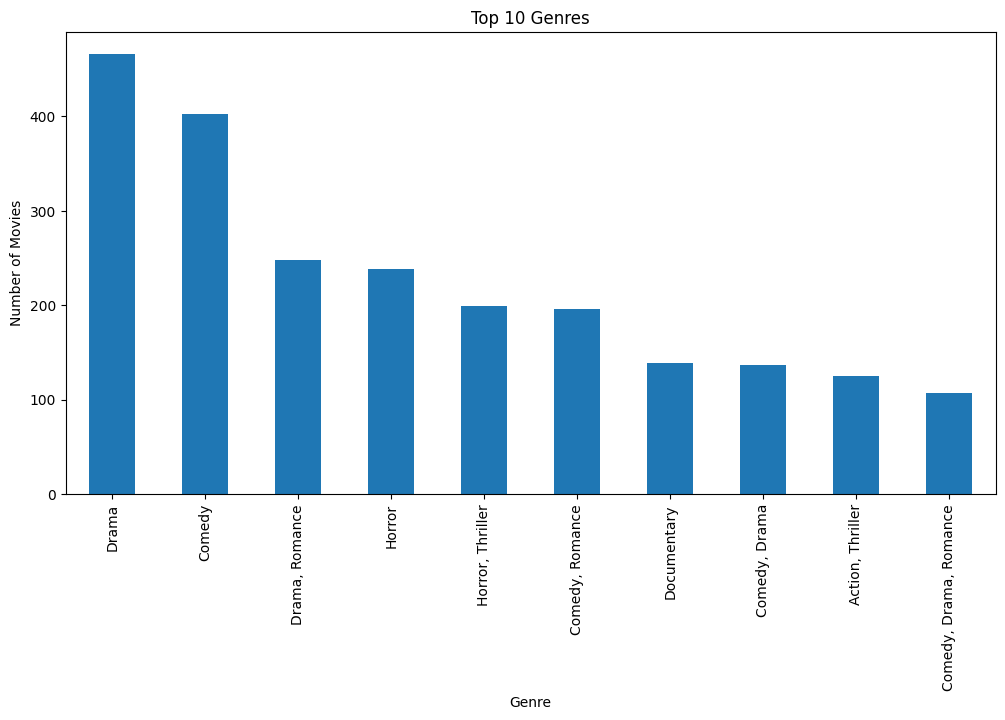

In [ ]:
plt.figure(figsize=(12,6))
df['Genre'].value_counts().head(10).plot(kind='bar')
plt.title("Top 10 Genres")
plt.xlabel("Genre")
plt.ylabel("Number of Movies")
plt.show()

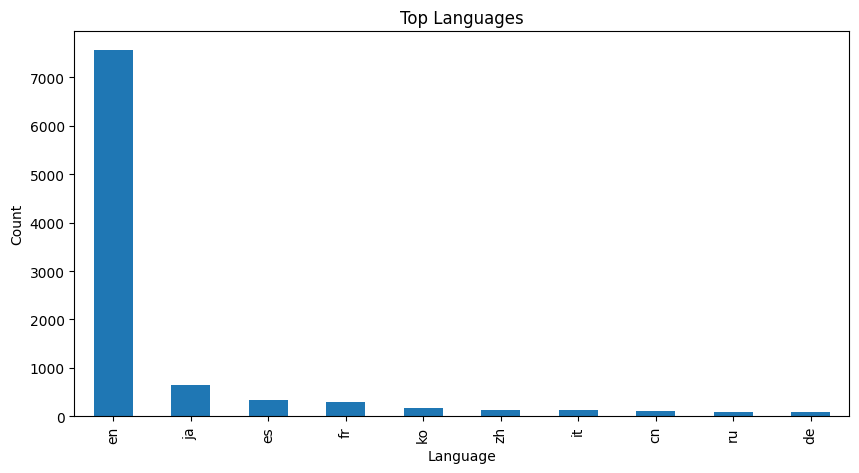

In [ ]:
plt.figure(figsize=(10,5))
df['Original_Language'].value_counts().head(10).plot(kind='bar')
plt.title("Top Languages")
plt.xlabel("Language")
plt.ylabel("Count")
plt.show()

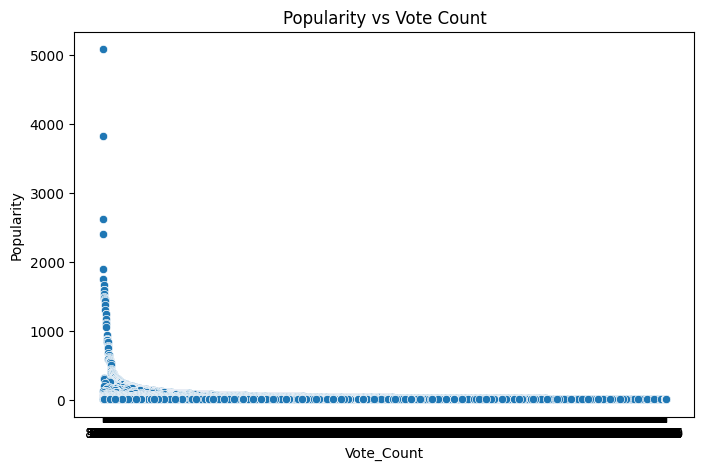

In [ ]:
plt.figure(figsize=(8,5))
sns.scatterplot(
    data=df,
    x='Vote_Count',
    y='Popularity'
)
plt.title("Popularity vs Vote Count")
plt.show()

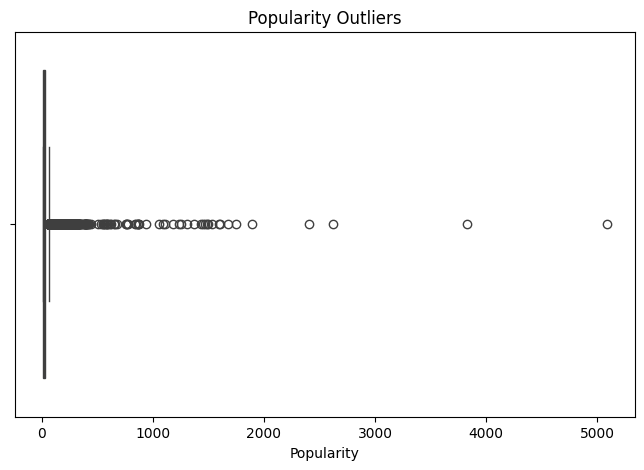

In [ ]:
plt.figure(figsize=(8,5))
sns.boxplot(x=df['Popularity'])
plt.title("Popularity Outliers")
plt.show()


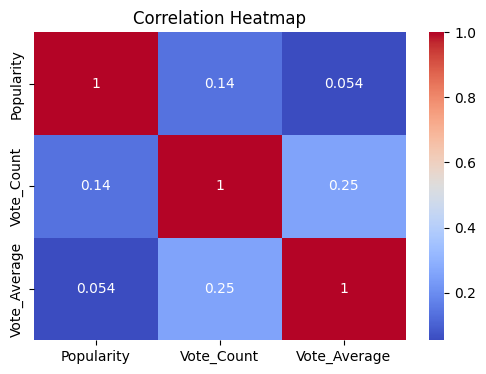

In [ ]:
plt.figure(figsize=(6,4))

corr = df[['Popularity',
           'Vote_Count',
           'Vote_Average']].corr()

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm'
)

plt.title("Correlation Heatmap")
plt.show()


In [ ]:
print("\n===== KEY INSIGHTS =====")
print("1. Drama is the most common genre.")
print("2. Most movies have ratings between 5 and 8.")
print("3. Popular movies generally receive more votes.")
print("4. A few movies are extremely popular outliers.")
print("5. English is expected to be the dominant language.")


===== KEY INSIGHTS =====
1. Drama is the most common genre.
2. Most movies have ratings between 5 and 8.
3. Popular movies generally receive more votes.
4. A few movies are extremely popular outliers.
5. English is expected to be the dominant language.


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

In [ ]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder

# Create a copy
model_df = df.copy()

# Convert Release_Date to datetime
model_df['Release_Date'] = pd.to_datetime(model_df['Release_Date'], errors='coerce')

# Convert datetime to ordinal number
model_df['Release_Date'] = model_df['Release_Date'].map(
    lambda x: x.toordinal() if pd.notnull(x) else 0
)

# Convert numeric columns stored as text
numeric_cols = ['Vote_Count', 'Vote_Average', 'Popularity']

for col in numeric_cols:
    model_df[col] = pd.to_numeric(model_df[col], errors='coerce')

# Fill missing values
model_df.fillna(0, inplace=True)

# Encode remaining categorical columns
le = LabelEncoder()

for col in model_df.select_dtypes(include='object').columns:
    model_df[col] = le.fit_transform(model_df[col].astype(str))

print(model_df.dtypes)

Release_Date           int64
Title                  int64
Overview               int64
Popularity           float64
Vote_Count             int64
Vote_Average         float64
Original_Language      int64
Genre                  int64
Poster_Url             int64
dtype: object


In [ ]:
X = model_df.drop("Popularity", axis=1)
y = model_df["Popularity"]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [ ]:
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

In [ ]:
y_pred = model.predict(X_test)

In [ ]:
print("MAE:", mean_absolute_error(y_test, y_pred))

print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))

print("R² Score:", r2_score(y_test, y_pred))

MAE: 24.005918957273654
RMSE: 116.9186474008907
R² Score: 0.4275755123103717


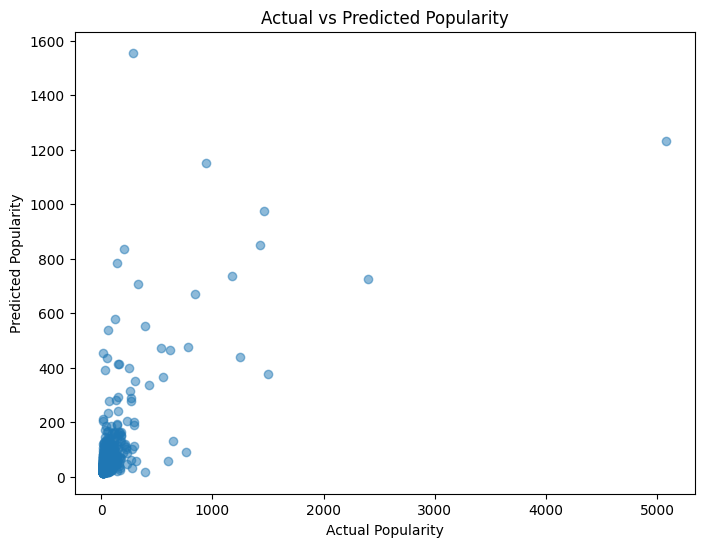

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.xlabel("Actual Popularity")
plt.ylabel("Predicted Popularity")
plt.title("Actual vs Predicted Popularity")
plt.show()